# NB03 - Analisis dan Evaluasi Hasil Simulasi

Notebook ini menghitung CIEDE2000 antara citra masukan dan hasil simulasi NB02 pada kelompok seleksi confusion line NB01. Laporan NB02 harus mencakup tepat empat severity untuk setiap pasangan citra dan tipe CVD yang dipilih NB01.

Hasil diekspor per citra, kelas buah, kelompok seleksi (`confusion_line_protan` atau `confusion_line_deutan`), dan kondisi simulasi. Kelompok seleksi menggantikan domain Red-Orange/Green-Yellow. Kelas buah dipertahankan sebagai metadata, tanpa menjadi subfolder citra simulasi.

Rata-rata kelompok protan dan deutan dapat berasal dari sampel berbeda. Perbandingan berpasangan tambahan hanya memakai citra yang dipilih untuk kedua tipe CVD pada severity yang sama, dengan verifikasi hash citra asli identik. Irisan tersebut belum tentu seimbang antar kelas.

Delta E dihitung pada seluruh piksel citra, termasuk latar, sesuai evaluasi sebelumnya. Nilai ini menggambarkan perubahan warna akibat simulasi, bukan validasi persepsi manusia atau ukuran langsung kesulitan mengenali buah.


In [1]:
%pip install opencv-python-headless numpy pandas matplotlib scikit-image -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Memuat Laporan Simulasi

In [2]:
from __future__ import annotations
import sys, time
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.color import deltaE_ciede2000
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/ tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv, write_json
RESEARCH_ROOT=find_research_root("notebooks/tanpa_segmentasi/02/output/simulation_report.csv")
SIMULATION_REPORT_PATH=RESEARCH_ROOT/"notebooks/tanpa_segmentasi/02/output/simulation_report.csv"
OUTPUT_DIR=RESEARCH_ROOT/"notebooks/tanpa_segmentasi/03/output"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CVD_FAMILIES=("protan","deutan")
SEVERITIES=(0.25,0.50,0.75,1.00)

SOURCE_KEY = ["subset", "source_class", "source_file_name"]
SELECTION_KEY = [*SOURCE_KEY, "cvd_family"]
JOB_KEY = [*SELECTION_KEY, "severity"]
simulation_report = pd.read_csv(SIMULATION_REPORT_PATH)
required = {*JOB_KEY, "input_path", "output_path", "input_sha256", "output_sha256", "selection_group", "selection_distance_median", "ambiguity_threshold"}
missing = required - set(simulation_report.columns)
if missing:
    raise ValueError(f"Jalankan NB02 terbaru. Kolom laporan belum lengkap: {sorted(missing)}")
if simulation_report.empty or simulation_report[list(required)].isna().any().any():
    raise ValueError("Laporan NB02 kosong atau memiliki nilai wajib yang kosong.")
if simulation_report.duplicated(JOB_KEY).any():
    raise ValueError("Laporan NB02 memiliki pasangan evaluasi berulang.")
selection_path = RESEARCH_ROOT / "notebooks/tanpa_segmentasi/01/output/confusion_line_selected_by_cvd.csv"
selection = pd.read_csv(selection_path)
if selection.empty or selection.duplicated(SELECTION_KEY).any():
    raise ValueError("Manifest seleksi NB01 kosong atau memiliki duplikat.")
expected = selection[SELECTION_KEY].merge(pd.DataFrame({"severity": SEVERITIES}), how="cross")
coverage = expected.merge(simulation_report[JOB_KEY], on=JOB_KEY, how="outer", indicator=True, validate="one_to_one")
if not coverage["_merge"].eq("both").all():
    raise ValueError("Laporan NB02 tidak sesuai seleksi NB01 atau severity belum lengkap. Jalankan ulang NB02.")
import json
with (SIMULATION_REPORT_PATH.parent / "simulation_summary.json").open(encoding="utf-8") as file:
    simulation_metadata = json.load(file)
if simulation_metadata.get("selection_manifest_sha256") != sha256_file(selection_path):
    raise ValueError("Manifest NB01 berubah sejak NB02 dijalankan. Jalankan ulang NB02.")
checked = simulation_report.merge(
    selection[[*SELECTION_KEY, "output_sha256"]].rename(columns={"output_sha256": "selected_input_sha256"}),
    on=SELECTION_KEY, validate="many_to_one",
)
if not checked["input_sha256"].eq(checked["selected_input_sha256"]).all():
    raise ValueError("Hash masukan NB02 berbeda dari seleksi NB01.")
if not simulation_report["selection_group"].eq("confusion_line_" + simulation_report["cvd_family"]).all():
    raise ValueError("Kelompok seleksi tidak sesuai tipe CVD.")
simulation_report = simulation_report.sort_values(JOB_KEY).reset_index(drop=True)
source_count = len(simulation_report[SOURCE_KEY].drop_duplicates())
print(f"Pasangan citra yang dievaluasi: {len(simulation_report)}")
print(simulation_report.groupby(["cvd_family", "severity"]).size().to_string())


Pasangan citra yang dievaluasi: 3648
cvd_family  severity
deutan      0.25        456
            0.50        456
            0.75        456
            1.00        456
protan      0.25        456
            0.50        456
            0.75        456
            1.00        456


## Tahap 2 - Menghitung ΔE00 Setiap Pasangan Citra


In [3]:
def mean_delta_e00(input_bgr: np.ndarray, output_bgr: np.ndarray) -> float:
    first=cv2.cvtColor(input_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    second=cv2.cvtColor(output_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    first[:,:,0]*=100.0/255.0; second[:,:,0]*=100.0/255.0
    first[:,:,1:]-=128.0; second[:,:,1:]-=128.0
    return float(deltaE_ciede2000(first,second).mean())

started = time.perf_counter()
evaluation_rows=[]
for index,row in simulation_report.iterrows():
    if sha256_file(Path(row["input_path"])) != row["input_sha256"] or sha256_file(Path(row["output_path"])) != row["output_sha256"]:
        raise ValueError(f"Hash citra berubah sejak NB02: {row['output_path']}")
    original=cv2.imread(row["input_path"],cv2.IMREAD_COLOR)
    simulated=cv2.imread(row["output_path"],cv2.IMREAD_COLOR)
    if original is None or simulated is None or original.shape != simulated.shape: raise ValueError(f"Pasangan citra tidak valid: {row['output_path']}")
    evaluation_rows.append({
        "subset": row["subset"],
        "source_class": row["source_class"],
        "source_file_name": row["source_file_name"],
        "selection_group": row["selection_group"],
        "selection_distance_median": row["selection_distance_median"],
        "ambiguity_threshold": row["ambiguity_threshold"],
        "input_sha256": row["input_sha256"],
        "cvd_family": row["cvd_family"],
        "severity": row["severity"],
        "input_path": row["input_path"],
        "output_path": row["output_path"],
        "mean_delta_e00": mean_delta_e00(original, simulated)
    })
    if (index+1)%1000==0 or index+1==len(simulation_report): print(f"{index+1}/{len(simulation_report)} pasangan dievaluasi, {time.perf_counter()-started:.1f} detik")
evaluation=pd.DataFrame(evaluation_rows).sort_values(["cvd_family","severity","source_class","source_file_name"]).reset_index(drop=True)
print(f"Rata-rata ΔE00 keseluruhan: {evaluation['mean_delta_e00'].mean():.4f}")


1000/3648 pasangan dievaluasi, 230.6 detik
2000/3648 pasangan dievaluasi, 553.9 detik
3000/3648 pasangan dievaluasi, 936.0 detik
3648/3648 pasangan dievaluasi, 1162.2 detik
Rata-rata ΔE00 keseluruhan: 9.0244


In [4]:
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def read_bgr(path: str) -> np.ndarray:
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Citra tidak dapat dibaca: {path}")
    return image


def calculate_delta_e00_map(
    original_bgr: np.ndarray,
    simulated_bgr: np.ndarray,
) -> np.ndarray:
    original_lab = cv2.cvtColor(
        original_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    simulated_lab = cv2.cvtColor(
        simulated_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    original_lab[:, :, 0] *= 100.0 / 255.0
    simulated_lab[:, :, 0] *= 100.0 / 255.0

    original_lab[:, :, 1:] -= 128.0
    simulated_lab[:, :, 1:] -= 128.0

    return deltaE_ciede2000(original_lab, simulated_lab)

In [5]:
def select_examples(group: pd.DataFrame) -> pd.DataFrame:
    cvd_family, severity = group.iloc[0][["cvd_family", "severity"]]

    ordered = group.sort_values(
        ["mean_delta_e00", "source_class", "source_file_name"]
    ).reset_index(drop=True)

    median_value = ordered["mean_delta_e00"].median()

    median_index = (
        (ordered["mean_delta_e00"] - median_value)
        .abs()
        .sort_values(kind="stable")
        .index[0]
    )

    examples = pd.concat(
        [
            ordered.iloc[[0]].assign(example_type="terendah"),
            ordered.loc[[median_index]].assign(
                example_type="mendekati_median"
            ),
            ordered.iloc[[-1]].assign(example_type="tertinggi"),
        ],
        ignore_index=True,
    )

    examples["cvd_family"] = cvd_family
    examples["severity"] = severity

    return examples.drop_duplicates(
        subset=[
            "source_class",
            "source_file_name",
            "cvd_family",
            "severity",
        ]
    )


representative_cases = pd.concat(
    [select_examples(group) for _, group in evaluation.groupby(["cvd_family", "severity"])],
    ignore_index=True,
)

write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    ["cvd_family", "severity", "example_type"],
)

representative_cases[
    [
        "cvd_family",
        "severity",
        "example_type",
        "selection_group",
        "source_class",
        "source_file_name",
        "mean_delta_e00",
    ]
]


,cvd_family,severity,example_type,selection_group,source_class,source_file_name,mean_delta_e00
0,deutan,0.25,terendah,confusion_line_deutan,018hami,31.png,0.313165
1,deutan,0.25,mendekati_median,confusion_line_deutan,007watermelon,221.png,4.053256
2,deutan,0.25,tertinggi,confusion_line_deutan,010pomegranate,68.png,9.228076
3,deutan,0.50,terendah,confusion_line_deutan,018hami,31.png,0.572683
4,deutan,0.50,mendekati_median,confusion_line_deutan,013grape,30.png,7.049969
5,deutan,0.50,tertinggi,confusion_line_deutan,010pomegranate,68.png,17.631734
6,deutan,0.75,terendah,confusion_line_deutan,018hami,31.png,0.743675
7,deutan,0.75,mendekati_median,confusion_line_deutan,007watermelon,134.png,9.170009
8,deutan,0.75,tertinggi,confusion_line_deutan,010pomegranate,68.png,24.494353
9,deutan,1.00,terendah,confusion_line_deutan,018hami,31.png,0.871924


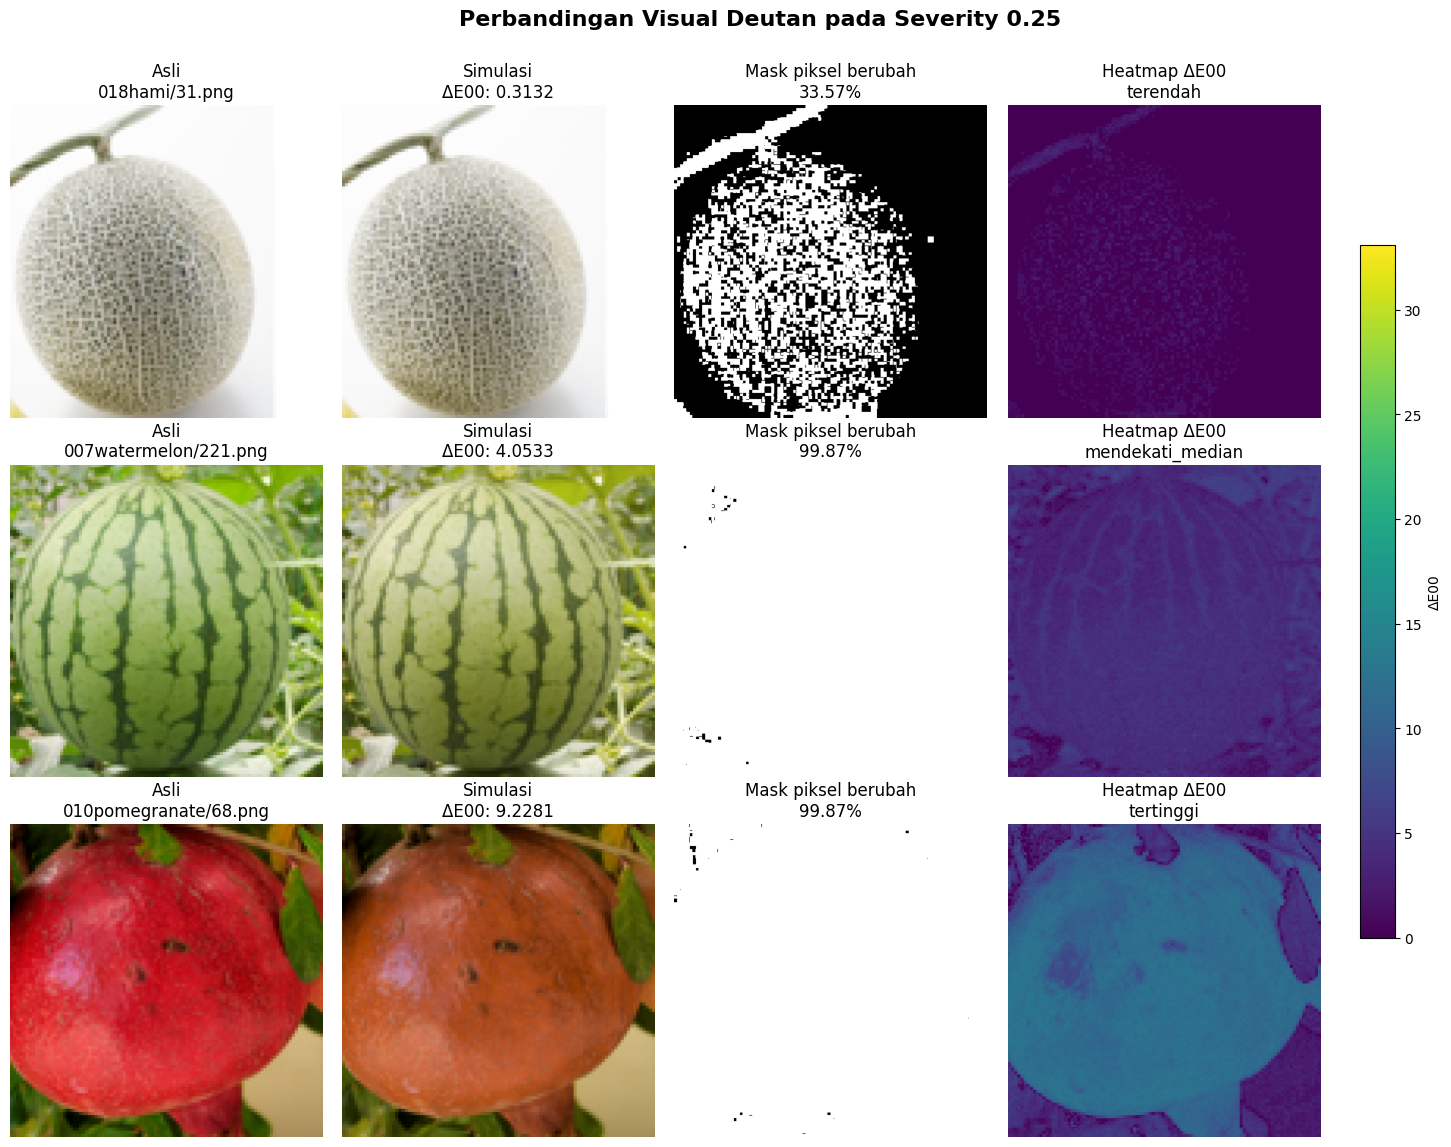

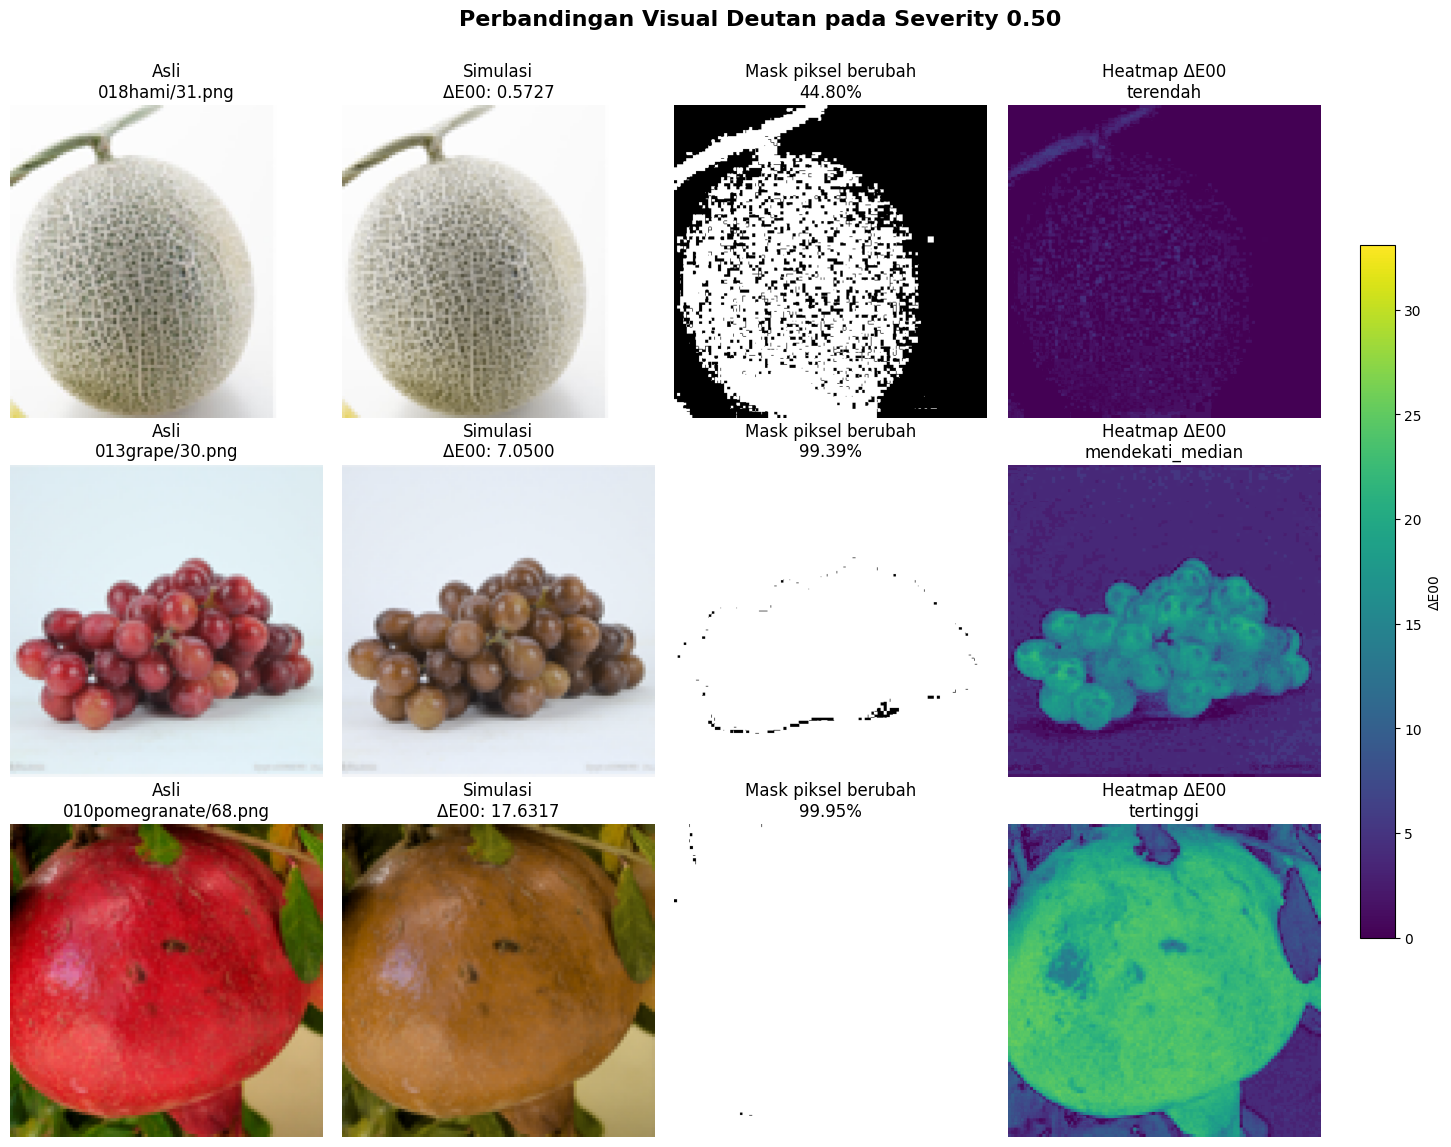

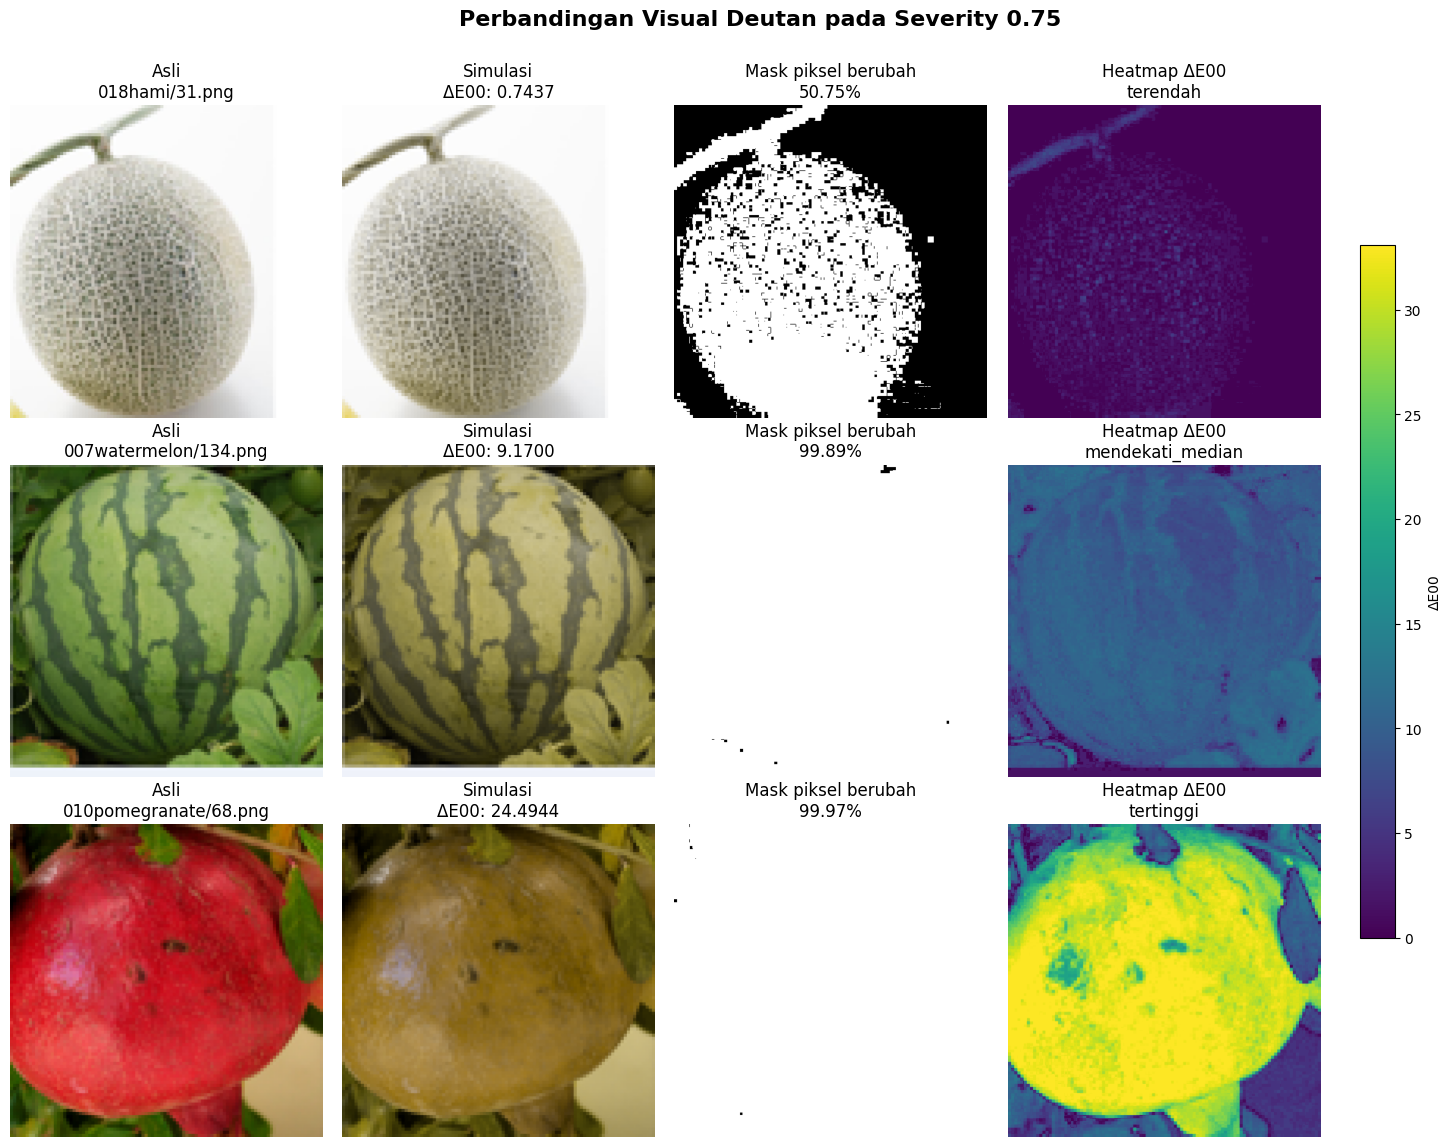

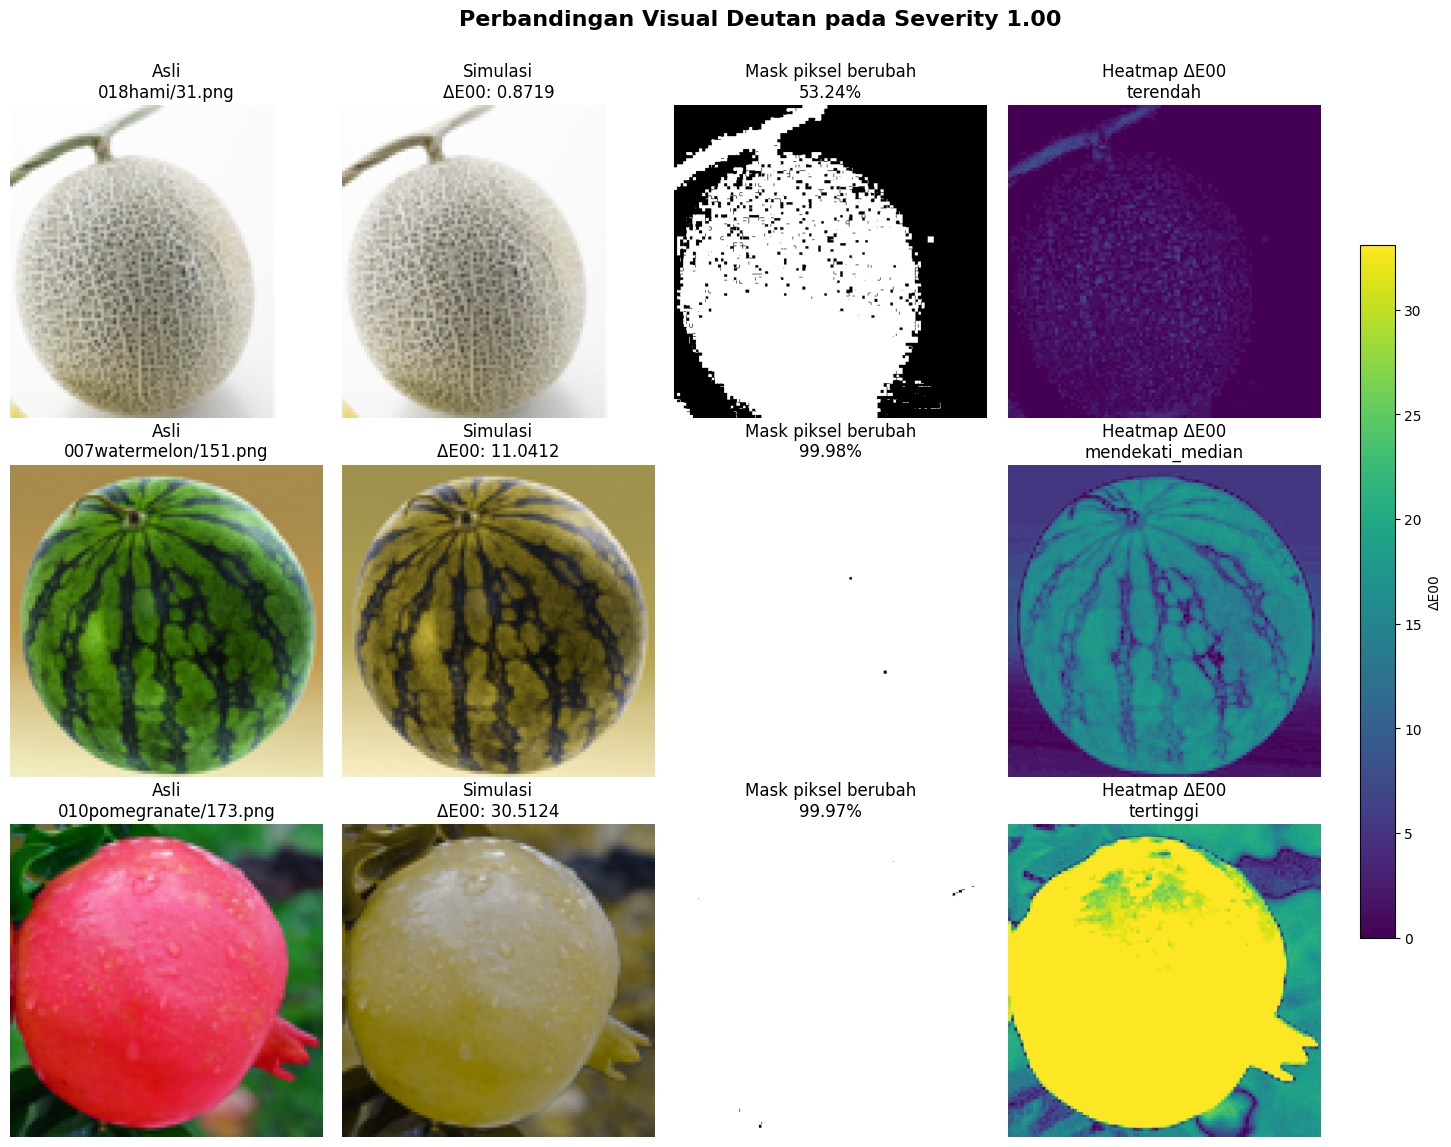

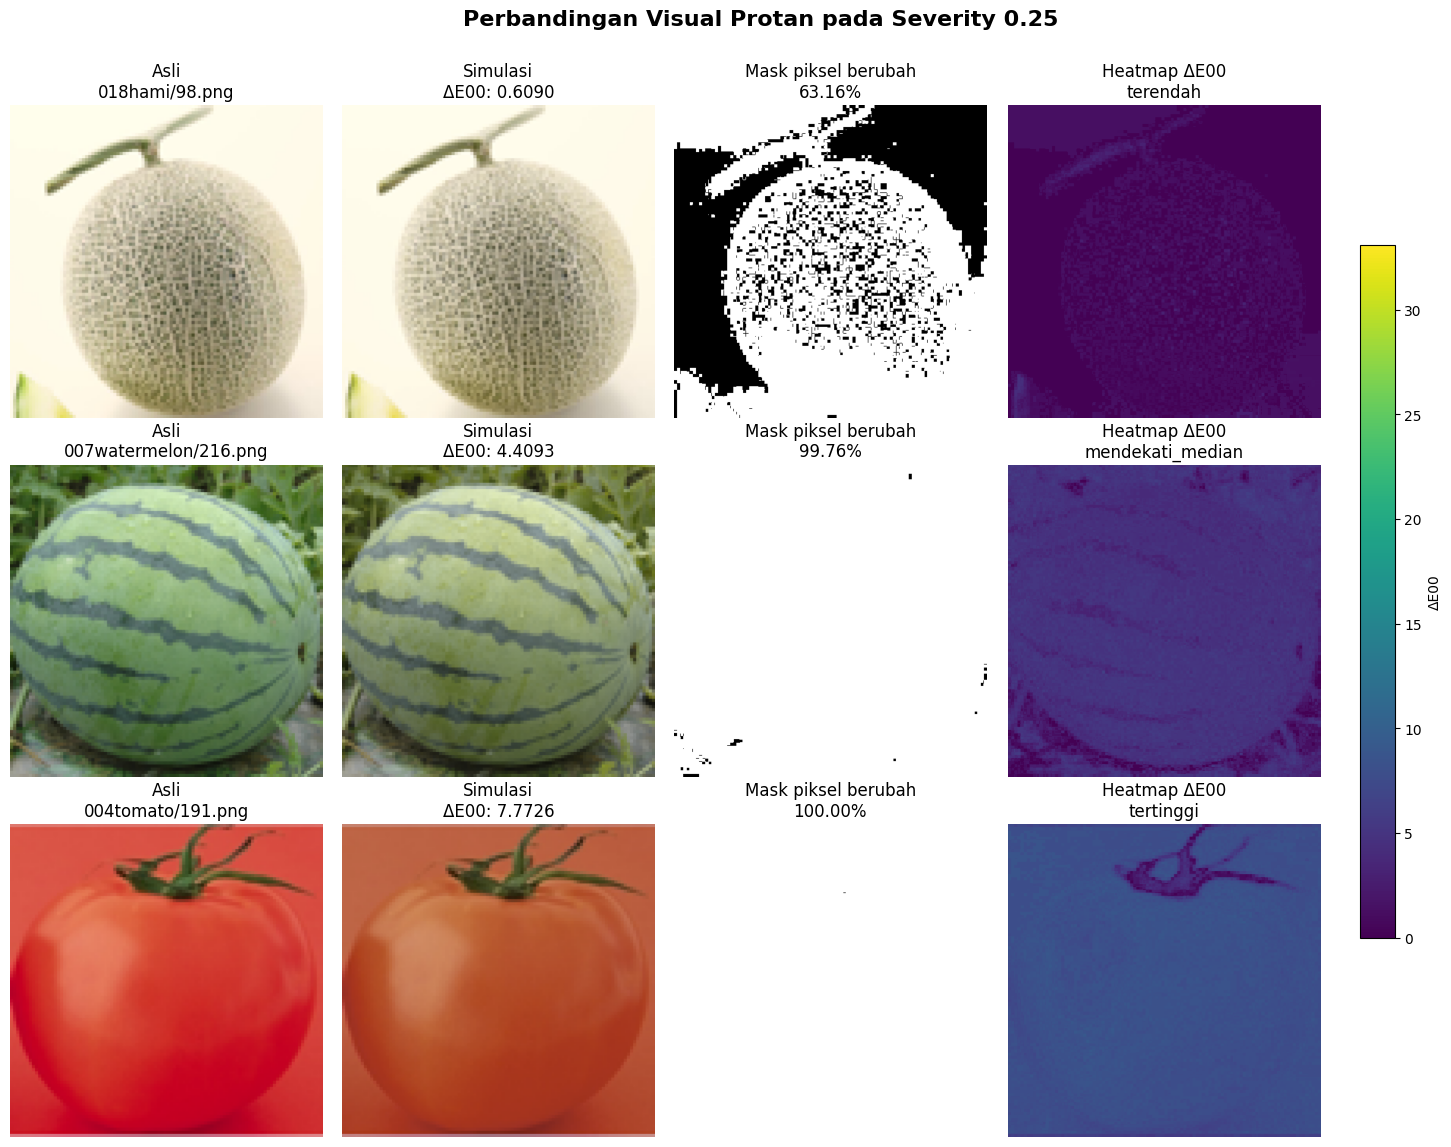

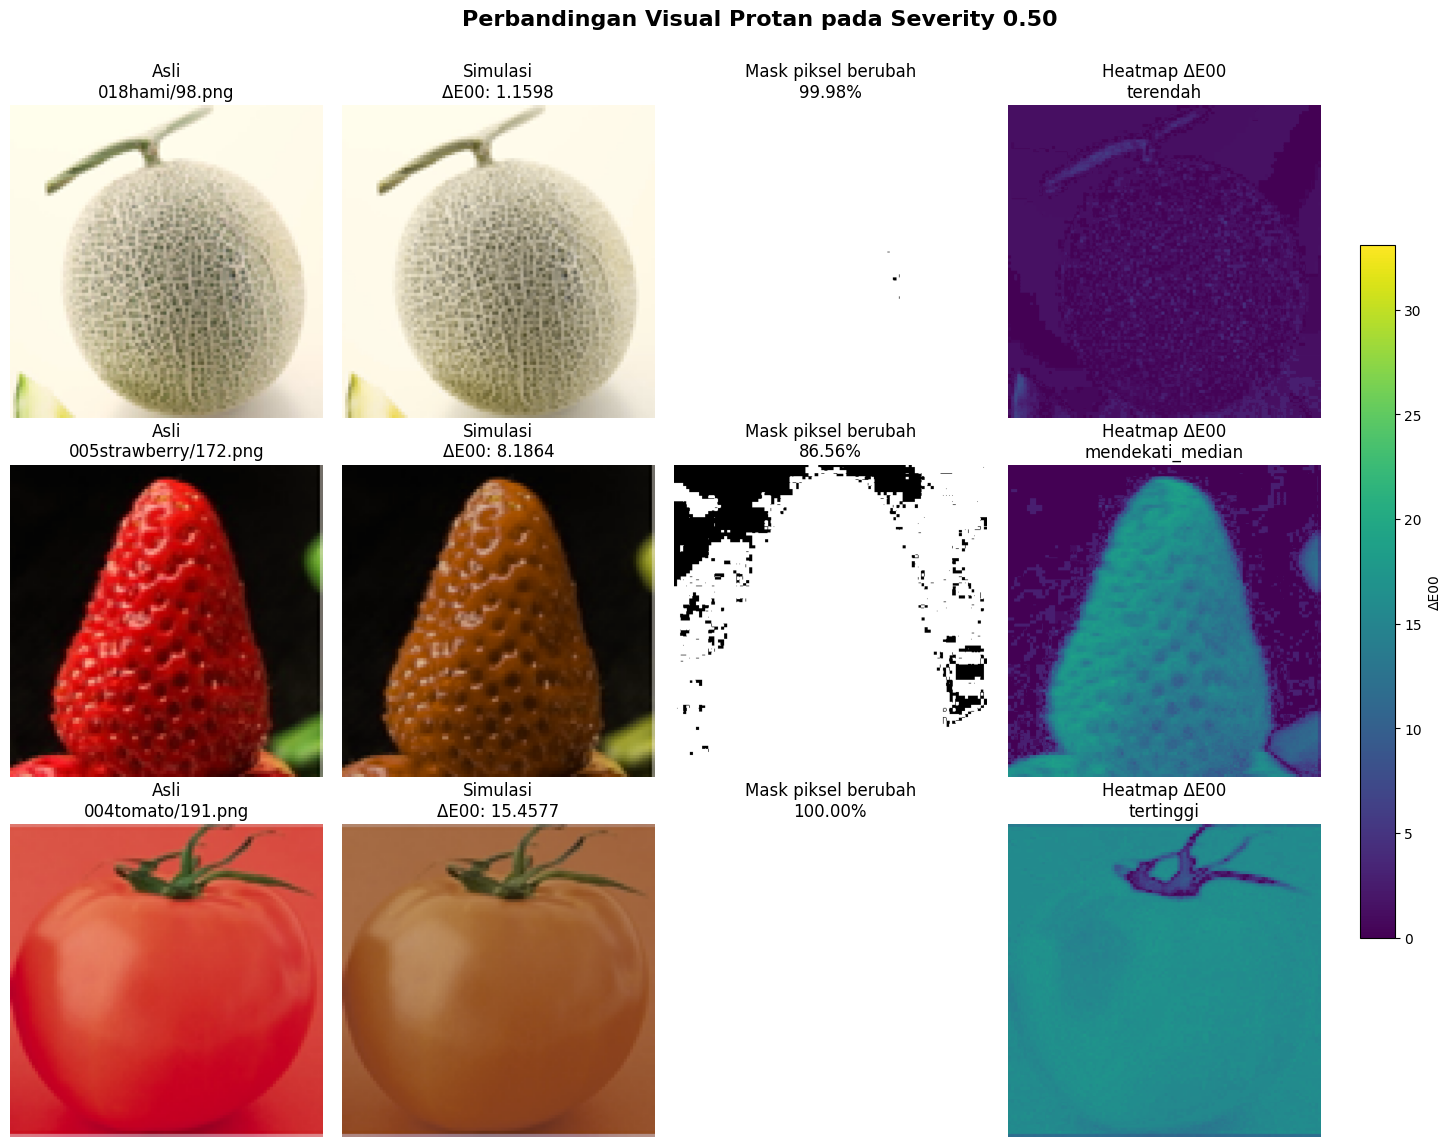

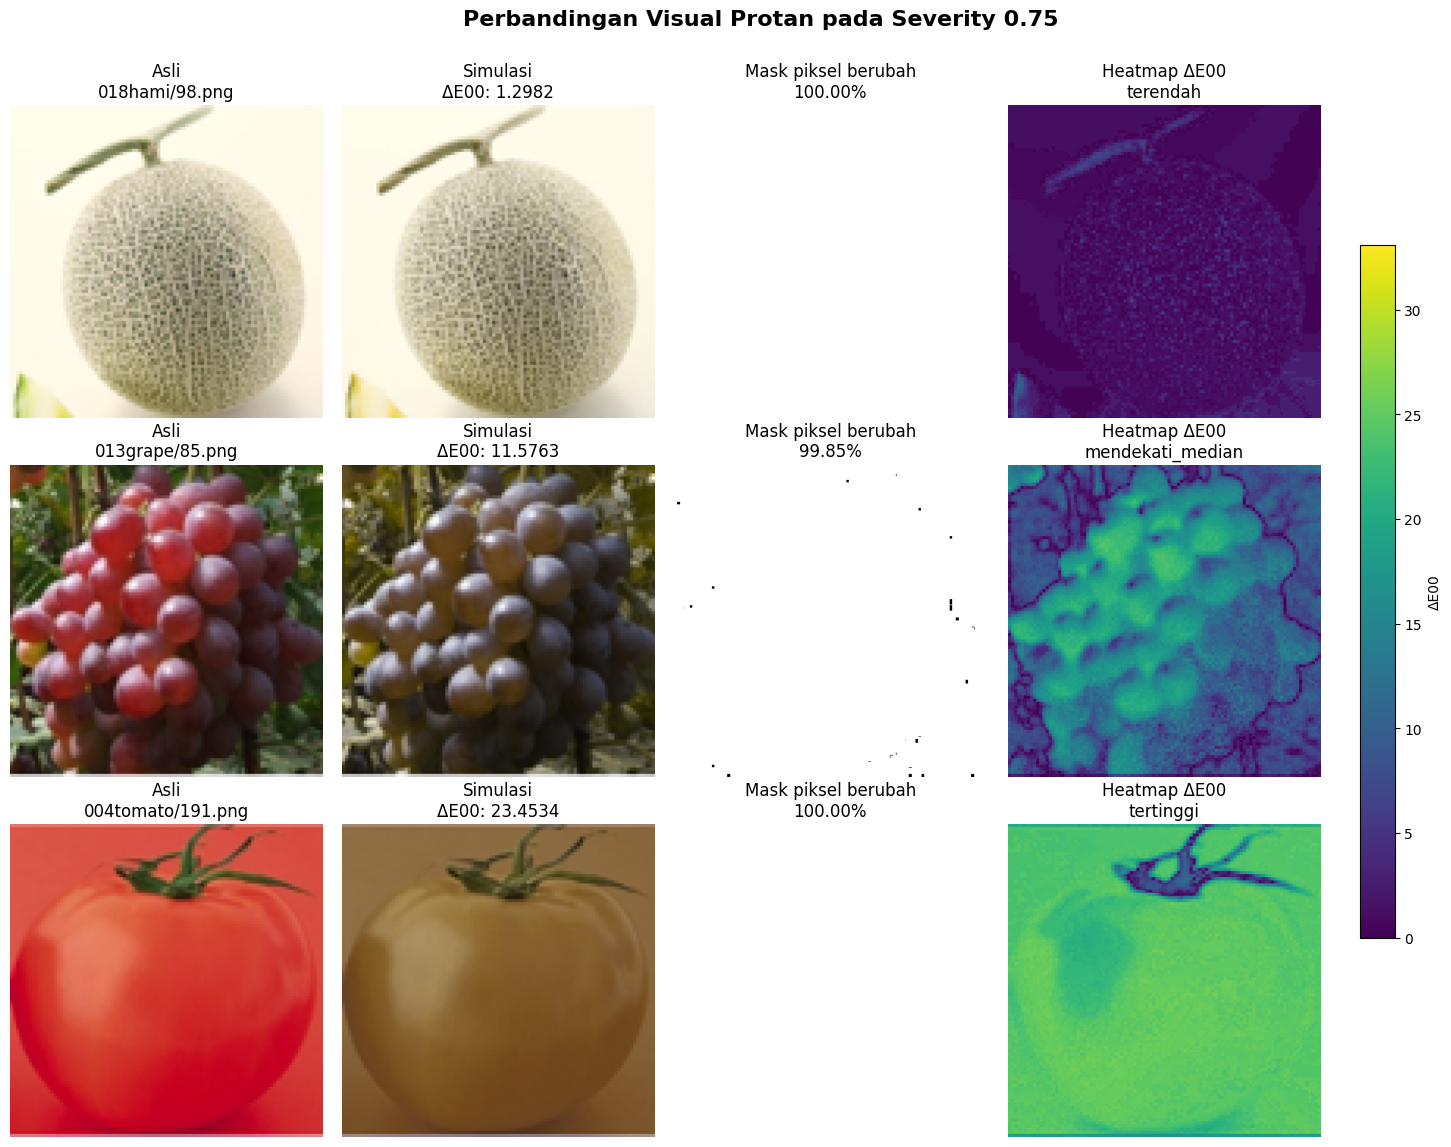

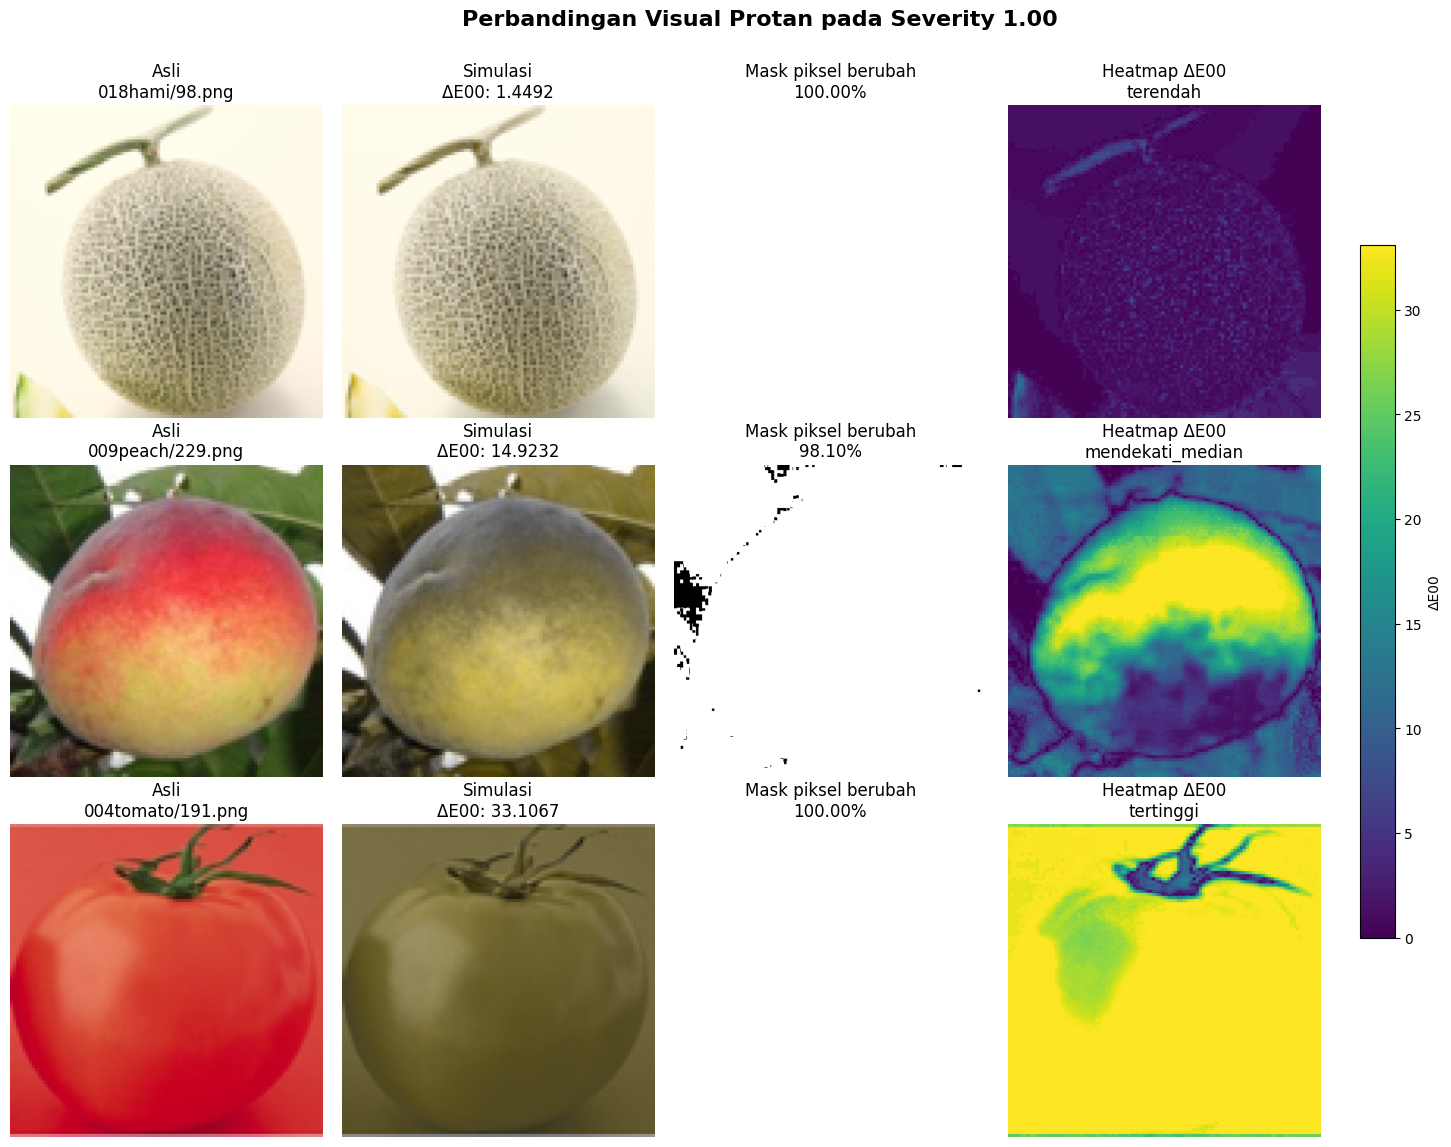

In [6]:
delta_e00_max = float(evaluation["mean_delta_e00"].max())

example_order = {
    "terendah": 0,
    "mendekati_median": 1,
    "tertinggi": 2,
}


def create_visual_panel(cases: pd.DataFrame) -> None:
    ordered_cases = cases.sort_values(
        "example_type",
        key=lambda values: values.map(example_order),
    )

    figure, axes = plt.subplots(len(ordered_cases), 4, figsize=(16, 4 * len(ordered_cases)), squeeze=False)

    for row_index, (_, item) in enumerate(ordered_cases.iterrows()):
        original_bgr = read_bgr(item["input_path"])
        simulated_bgr = read_bgr(item["output_path"])

        delta_e00_map = calculate_delta_e00_map(
            original_bgr,
            simulated_bgr,
        )

        changed_mask = np.any(
            original_bgr != simulated_bgr,
            axis=2,
        )

        axes[row_index, 0].imshow(
            cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 0].set_title(
            f"Asli\n{item['source_class']}/{item['source_file_name']}"
        )

        axes[row_index, 1].imshow(
            cv2.cvtColor(simulated_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 1].set_title(
            f"Simulasi\nΔE00: {item['mean_delta_e00']:.4f}"
        )

        axes[row_index, 2].imshow(
            changed_mask,
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row_index, 2].set_title(
            f"Mask piksel berubah\n{changed_mask.mean():.2%}"
        )

        heatmap = axes[row_index, 3].imshow(
            delta_e00_map,
            cmap="viridis",
            vmin=0,
            vmax=delta_e00_max,
        )
        axes[row_index, 3].set_title(
            f"Heatmap ΔE00\n{item['example_type']}"
        )

        for axis in axes[row_index]:
            axis.axis("off")

    figure.colorbar(
        heatmap,
        ax=axes[:, 3],
        shrink=0.75,
        label="ΔE00",
    )

    cvd_family = ordered_cases.iloc[0]["cvd_family"]
    severity = ordered_cases.iloc[0]["severity"]

    figure.suptitle(
        f"Perbandingan Visual {cvd_family.title()} "
        f"pada Severity {severity:.2f}",
        fontsize=16,
        fontweight="bold",
    )

    figure.subplots_adjust(
        top=0.90,
        bottom=0.04,
        left=0.03,
        right=0.85,
        hspace=0.15,
        wspace=0.05,
    )

    output_path = (
        FIGURE_DIR
        / f"visual_{cvd_family}_severity_{int(severity * 100):03d}.png"
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)


for _, cases in representative_cases.groupby(
    ["cvd_family", "severity"],
):
    create_visual_panel(cases)


## Tahap 3 - Agregasi Metrik 4 Level, Visualisasi, dan Ekspor Hasil Bab 5


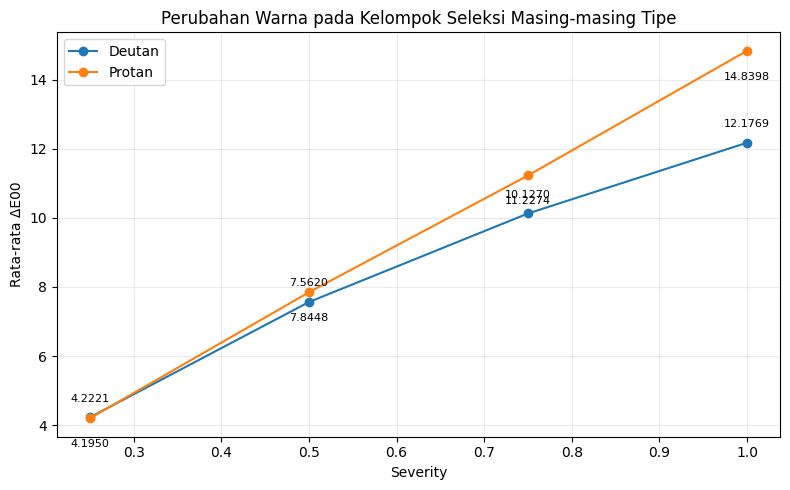

,cvd_family,severity,image_count,mean_delta_e00,std_delta_e00,median_delta_e00,minimum_delta_e00,maximum_delta_e00
0,deutan,0.25,456,4.222091,2.081197,4.054595,0.313165,9.228076
1,deutan,0.50,456,7.562023,4.030120,7.078783,0.572683,17.631734
2,deutan,0.75,456,10.126970,5.684114,9.244961,0.743675,24.494353
3,deutan,1.00,456,12.176925,7.016020,11.021607,0.871924,30.512386
4,protan,0.25,456,4.195047,1.621924,4.410624,0.608973,7.772647
5,protan,0.50,456,7.844814,3.253823,8.191442,1.159846,15.457719
6,protan,0.75,456,11.227442,4.994627,11.582538,1.298190,23.453378
7,protan,1.00,456,14.839839,7.177151,14.948641,1.449180,33.106662


In [7]:
# ==============================================================================
# PERHITUNGAN METRIK 4 LEVEL UNTUK KELENGKAPAN TABEL BAB 5
# ==============================================================================

# Level 1: Per Individu (Tiap Pasangan Citra Asli vs Simulasi)
write_csv(
    evaluation,
    OUTPUT_DIR / "evaluation_individual.csv",
    ["cvd_family", "severity", "source_class", "source_file_name"]
)
write_csv(
    evaluation,
    OUTPUT_DIR / "simulation_evaluation.csv",
    ["cvd_family", "severity", "source_class", "source_file_name"]
)

# Level 2: Per Kelas Buah (mean, std, median, min, max)
class_summary = evaluation.groupby(
    ["cvd_family", "severity", "selection_group", "source_class"], as_index=False
).agg(
    image_count=("mean_delta_e00", "size"),
    mean_delta_e00=("mean_delta_e00", "mean"),
    std_delta_e00=("mean_delta_e00", lambda values: float(values.std()) if len(values) > 1 else ""),
    median_delta_e00=("mean_delta_e00", "median"),
    minimum_delta_e00=("mean_delta_e00", "min"),
    maximum_delta_e00=("mean_delta_e00", "max")
)
write_csv(
    class_summary,
    OUTPUT_DIR / "evaluation_class_summary.csv",
    ["cvd_family", "severity", "selection_group", "source_class"]
)

# Level 3: Per Kelompok Seleksi (mean, std, median, min, max)
selection_summary = evaluation.groupby(
    ["cvd_family", "severity", "selection_group"], as_index=False
).agg(
    image_count=("mean_delta_e00", "size"),
    mean_delta_e00=("mean_delta_e00", "mean"),
    std_delta_e00=("mean_delta_e00", lambda values: float(values.std()) if len(values) > 1 else ""),
    median_delta_e00=("mean_delta_e00", "median"),
    minimum_delta_e00=("mean_delta_e00", "min"),
    maximum_delta_e00=("mean_delta_e00", "max")
)
write_csv(
    selection_summary,
    OUTPUT_DIR / "evaluation_selection_summary.csv",
    ["cvd_family", "severity", "selection_group"]
)

# Level 4: Global / Keseluruhan Kondisi (mean, std, median, min, max)
group_summary = evaluation.groupby(
    ["cvd_family", "severity"], as_index=False
).agg(
    image_count=("mean_delta_e00", "size"),
    mean_delta_e00=("mean_delta_e00", "mean"),
    std_delta_e00=("mean_delta_e00", lambda values: float(values.std()) if len(values) > 1 else ""),
    median_delta_e00=("mean_delta_e00", "median"),
    minimum_delta_e00=("mean_delta_e00", "min"),
    maximum_delta_e00=("mean_delta_e00", "max")
)
write_csv(
    group_summary,
    OUTPUT_DIR / "evaluation_group_summary.csv",
    ["cvd_family", "severity"]
)
write_csv(
    group_summary,
    OUTPUT_DIR / "evaluation_global_summary.csv",
    ["cvd_family", "severity"]
)

# Ekspor Kasus Representatif (Terendah, Median, Tertinggi)
write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    ["cvd_family", "severity", "example_type"]
)

# Ekspor Ringkasan JSON
write_json({
    "total_evaluations": len(evaluation),
    "global_mean_delta_e00": float(evaluation["mean_delta_e00"].mean()),
    "global_std_delta_e00": float(evaluation["mean_delta_e00"].std()) if len(evaluation) > 1 else None,
    "metric_region": "whole_image_including_background",
    "selection_manifest_sha256": sha256_file(selection_path),
    "comparison_scope": "Different selected cohorts; paired comparison is exported separately",
    "global_min_delta_e00": float(evaluation["mean_delta_e00"].min()),
    "global_max_delta_e00": float(evaluation["mean_delta_e00"].max()),
    "levels_exported": [
        "Level 1: evaluation_individual.csv (per individu)",
        "Level 2: evaluation_class_summary.csv (per kelas)",
        "Level 3: evaluation_selection_summary.csv (per kelompok seleksi)",
        "Level 4: evaluation_group_summary.csv / evaluation_global_summary.csv (global)"
    ]
}, OUTPUT_DIR / "evaluation_summary.json")

# Visualisasi Kurva Severity vs Mean Delta E00
plt.figure(figsize=(8, 5))
for family, group in group_summary.groupby("cvd_family"):
    group = group.sort_values("severity")
    line, = plt.plot(
        group["severity"],
        group["mean_delta_e00"],
        marker="o",
        label=family.title()
    )
    if family.lower() == "protan":
        offset = (0, -15)
        va = "top"
    elif family.lower() == "deutan":
        offset = (0, 10)
        va = "bottom"
    else:
        offset = (0, 10)
        va = "bottom"

    for x, y in zip(group["severity"], group["mean_delta_e00"]):
        plt.annotate(
            f"{y:.4f}",
            (x, y),
            textcoords="offset points",
            xytext=offset,
            ha="center",
            va=va,
            fontsize=8
        )

plt.xlabel("Severity")
plt.ylabel("Rata-rata ΔE00")
plt.title("Perubahan Warna pada Kelompok Seleksi Masing-masing Tipe")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "mean_delta_e00_by_condition.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

group_summary


## Tahap 4 - Perbandingan Berpasangan pada Irisan Citra

Perbandingan hanya menggunakan citra dengan identitas dan hash masukan yang sama pada protan dan deutan. Tabel ringkasan utama memisahkan kedua tipe menjadi delapan baris, yaitu satu baris untuk setiap kombinasi tipe dan severity. Setiap baris merangkum nilai dari citra berpasangan. Selisih rata-rata deutan terhadap protan disimpan dalam tabel terpisah per severity. Grafik menampilkan rata-rata tiap tipe dari irisan sumber yang sama. Analisis ini bersifat deskriptif dan tidak memvalidasi persepsi manusia. Jika tidak ada irisan, CSV tetap diekspor dengan kolom yang sesuai dan grafik dilewati.

Citra unik pada irisan kedua kelompok: 130


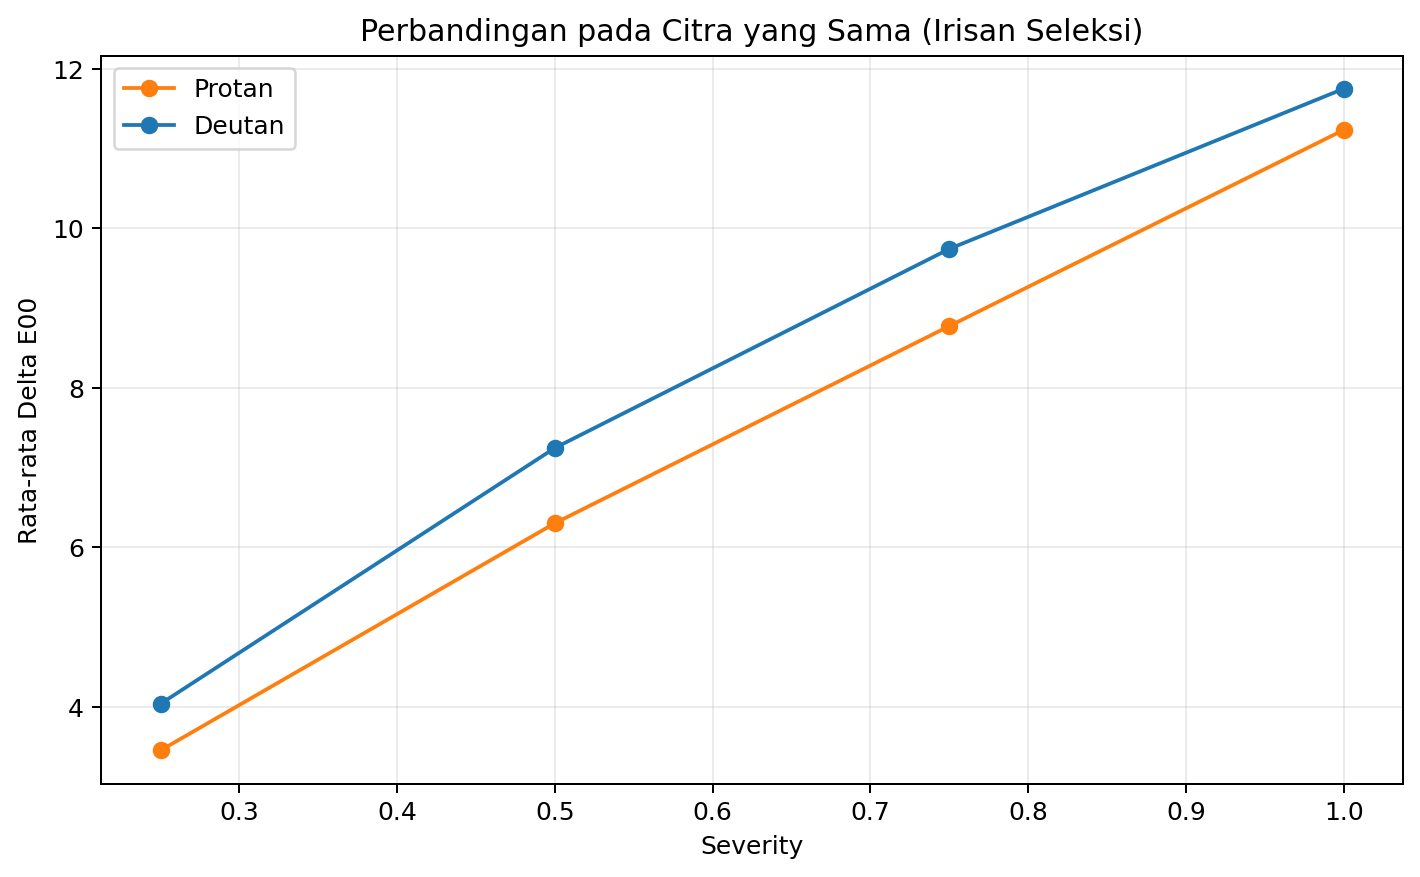

cvd_family,severity,paired_image_count,mean_delta_e00,std_delta_e00,median_delta_e00,minimum_delta_e00,maximum_delta_e00
deutan,0.25,130,4.040220,2.096728,4.007999,0.489056,9.228076
deutan,0.50,130,7.248340,4.050701,6.869035,0.858896,17.631734
deutan,0.75,130,9.743570,5.714732,9.033436,1.225816,24.494353
deutan,1.00,130,11.751481,7.068560,10.805787,1.486772,29.890834
protan,0.25,130,3.456185,1.595059,3.434731,0.608973,6.529263
protan,0.50,130,6.305295,3.083395,6.310514,1.159846,12.555907
protan,0.75,130,8.775899,4.554528,8.632644,1.298190,18.955357
protan,1.00,130,11.235170,6.288830,10.881670,1.449180,26.895635


In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Temukan evaluasi terakhir, baik notebook dibuka dari root proyek maupun folder notebook.
current_dir = Path.cwd()
output_candidates = []
for base_dir in (current_dir, *current_dir.parents):
    output_candidates.extend([
        base_dir / "research/notebooks/tanpa_segmentasi/03/output",
        base_dir / "output",
    ])
OUTPUT_DIR = next(
    (candidate for candidate in output_candidates if (candidate / "evaluation_individual.csv").is_file()),
    None,
)
if OUTPUT_DIR is None:
    raise FileNotFoundError("evaluation_individual.csv tidak ditemukan pada folder keluaran NB03.")

evaluation = pd.read_csv(OUTPUT_DIR / "evaluation_individual.csv")
SOURCE_KEY = ["subset", "source_class", "source_file_name"]
PAIR_KEY = [*SOURCE_KEY, "severity"]
required_columns = {*PAIR_KEY, "input_sha256", "cvd_family", "mean_delta_e00"}
missing_columns = required_columns - set(evaluation.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak tersedia dalam hasil evaluasi: {sorted(missing_columns)}")

paired_columns = [*PAIR_KEY, "input_sha256", "mean_delta_e00"]
protan = evaluation.loc[evaluation["cvd_family"].eq("protan"), paired_columns]
deutan = evaluation.loc[evaluation["cvd_family"].eq("deutan"), paired_columns]
paired = protan.merge(
    deutan,
    on=PAIR_KEY,
    suffixes=("_protan", "_deutan"),
    validate="one_to_one",
)
if not paired["input_sha256_protan"].eq(paired["input_sha256_deutan"]).all():
    raise ValueError("Citra beridentitas sama memiliki isi berbeda pada kedua kelompok.")
paired["deutan_minus_protan_delta_e00"] = (
    paired["mean_delta_e00_deutan"] - paired["mean_delta_e00_protan"]
)
paired.to_csv(OUTPUT_DIR / "evaluation_paired_images.csv", index=False)

# Bentuk ringkasan delapan kondisi dengan satu tipe pada setiap baris.
paired_long = pd.concat(
    [
        paired[[*PAIR_KEY, "mean_delta_e00_protan"]]
        .rename(columns={"mean_delta_e00_protan": "mean_delta_e00"})
        .assign(cvd_family="protan"),
        paired[[*PAIR_KEY, "mean_delta_e00_deutan"]]
        .rename(columns={"mean_delta_e00_deutan": "mean_delta_e00"})
        .assign(cvd_family="deutan"),
    ],
    ignore_index=True,
)
summary_columns = [
    "cvd_family", "severity", "paired_image_count", "mean_delta_e00",
    "std_delta_e00", "median_delta_e00", "minimum_delta_e00", "maximum_delta_e00",
]
if paired_long.empty:
    paired_summary = pd.DataFrame(columns=summary_columns)
else:
    paired_summary = (
        paired_long.groupby(["cvd_family", "severity"], as_index=False)
        .agg(
            paired_image_count=("mean_delta_e00", "size"),
            mean_delta_e00=("mean_delta_e00", "mean"),
            std_delta_e00=("mean_delta_e00", "std"),
            median_delta_e00=("mean_delta_e00", "median"),
            minimum_delta_e00=("mean_delta_e00", "min"),
            maximum_delta_e00=("mean_delta_e00", "max"),
        )
        .reindex(columns=summary_columns)
        .sort_values(["cvd_family", "severity"])
        .reset_index(drop=True)
    )
paired_summary.to_csv(OUTPUT_DIR / "evaluation_paired_summary.csv", index=False)

# Simpan selisih rata-rata tipe secara terpisah untuk setiap severity.
difference_columns = [
    "severity", "paired_image_count", "mean_protan_delta_e00",
    "mean_deutan_delta_e00", "mean_deutan_minus_protan",
    "median_deutan_minus_protan",
]
if paired.empty:
    paired_difference_summary = pd.DataFrame(columns=difference_columns)
else:
    paired_difference_summary = (
        paired.groupby("severity", as_index=False)
        .agg(
            paired_image_count=("deutan_minus_protan_delta_e00", "size"),
            mean_protan_delta_e00=("mean_delta_e00_protan", "mean"),
            mean_deutan_delta_e00=("mean_delta_e00_deutan", "mean"),
            mean_deutan_minus_protan=("deutan_minus_protan_delta_e00", "mean"),
            median_deutan_minus_protan=("deutan_minus_protan_delta_e00", "median"),
        )
        .reindex(columns=difference_columns)
        .sort_values("severity")
        .reset_index(drop=True)
    )
paired_difference_summary.to_csv(
    OUTPUT_DIR / "evaluation_paired_difference_summary.csv", index=False
)
print(f"Citra unik pada irisan kedua kelompok: {paired[SOURCE_KEY].drop_duplicates().shape[0]}")

if not paired_summary.empty:
    paired_plot = paired_summary.pivot(
        index="severity", columns="cvd_family", values="mean_delta_e00"
    ).sort_index()
    colors = {"protan": "#ff7f0e", "deutan": "#1f77b4"}
    fig, ax = plt.subplots(figsize=(8, 5))
    for family in ("protan", "deutan"):
        if family in paired_plot.columns:
            ax.plot(
                paired_plot.index,
                paired_plot[family],
                marker="o",
                label=family.title(),
                color=colors[family],
            )
    ax.set(
        xlabel="Severity",
        ylabel="Rata-rata Delta E00",
        title="Perbandingan pada Citra yang Sama (Irisan Seleksi)",
    )
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "paired_mean_delta_e00_by_condition.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)
else:
    print("Tidak ada irisan citra; perbandingan berpasangan tidak tersedia.")
paired_summary


## Tahap 5 - Daftar Citra yang Hanya Lolos Satu Tipe

Sel ini memisahkan citra yang hanya terpilih pada protan dan citra yang hanya terpilih pada deutan berdasarkan manifest seleksi NB01. Hasilnya disimpan sebagai `confusion_line_protan_only_images.csv` dan `confusion_line_deutan_only_images.csv` di folder keluaran NB03. Sel ini dapat dijalankan mandiri dan tidak memerlukan variabel dari sel sebelumnya.

In [1]:
from pathlib import Path
import pandas as pd

# Find the NB01 selection manifest from the current folder or its parents.
current_dir = Path.cwd()
manifest_candidates = []
for base_dir in (current_dir, *current_dir.parents):
    manifest_candidates.extend([
        base_dir / "research/notebooks/tanpa_segmentasi/01/output/confusion_line_selected_by_cvd.csv",
        base_dir / "../01/output/confusion_line_selected_by_cvd.csv",
    ])
selection_path = next(
    (candidate.resolve() for candidate in manifest_candidates if candidate.is_file()),
    None,
)
if selection_path is None:
    raise FileNotFoundError("Manifest confusion_line_selected_by_cvd.csv NB01 tidak ditemukan.")

# Save both exclusive groups alongside the NB03 evaluation files.
output_candidates = []
for base_dir in (current_dir, *current_dir.parents):
    output_candidates.extend([
        base_dir / "research/notebooks/tanpa_segmentasi/03/output",
        base_dir / "output",
    ])
OUTPUT_DIR = next(
    (candidate.resolve() for candidate in output_candidates if candidate.is_dir()),
    None,
)
if OUTPUT_DIR is None:
    raise FileNotFoundError("Folder keluaran NB03 tidak ditemukan. Jalankan tahap evaluasi terlebih dahulu.")

selection = pd.read_csv(selection_path)
SOURCE_KEY = ["subset", "source_class", "source_file_name"]
required_columns = {*SOURCE_KEY, "cvd_family"}
missing_columns = required_columns - set(selection.columns)
if missing_columns:
    raise ValueError(f"Kolom manifest seleksi tidak tersedia: {sorted(missing_columns)}")
if selection.empty or selection[list(required_columns)].isna().any().any():
    raise ValueError("Manifest seleksi kosong atau memiliki identitas citra/tipe yang kosong.")
if not selection["cvd_family"].isin(["protan", "deutan"]).all():
    raise ValueError("Manifest seleksi memuat tipe CVD selain protan dan deutan.")
if selection.duplicated([*SOURCE_KEY, "cvd_family"]).any():
    raise ValueError("Manifest seleksi memiliki entri citra berulang untuk tipe yang sama.")

# Classify each source by whether it was selected for each CVD family.
source_membership = selection[[*SOURCE_KEY, "cvd_family"]].drop_duplicates()
protan_sources = source_membership.loc[source_membership["cvd_family"].eq("protan"), SOURCE_KEY]
deutan_sources = source_membership.loc[source_membership["cvd_family"].eq("deutan"), SOURCE_KEY]
protan_only_keys = protan_sources.merge(deutan_sources, on=SOURCE_KEY, how="left", indicator=True)
protan_only_keys = protan_only_keys.loc[protan_only_keys["_merge"].eq("left_only"), SOURCE_KEY]
deutan_only_keys = deutan_sources.merge(protan_sources, on=SOURCE_KEY, how="left", indicator=True)
deutan_only_keys = deutan_only_keys.loc[deutan_only_keys["_merge"].eq("left_only"), SOURCE_KEY]

protan_only = selection.loc[
    selection["cvd_family"].eq("protan")
].merge(protan_only_keys, on=SOURCE_KEY, how="inner", validate="many_to_one")
deutan_only = selection.loc[
    selection["cvd_family"].eq("deutan")
].merge(deutan_only_keys, on=SOURCE_KEY, how="inner", validate="many_to_one")

protan_only_path = OUTPUT_DIR / "confusion_line_protan_only_images.csv"
deutan_only_path = OUTPUT_DIR / "confusion_line_deutan_only_images.csv"
protan_only.to_csv(protan_only_path, index=False)
deutan_only.to_csv(deutan_only_path, index=False)

print(f"Citra protan saja: {len(protan_only)} -> {protan_only_path.name}")
print(f"Citra deutan saja: {len(deutan_only)} -> {deutan_only_path.name}")
display(protan_only.head(), deutan_only.head())

Citra protan saja: 326 -> confusion_line_protan_only_images.csv
Citra deutan saja: 326 -> confusion_line_deutan_only_images.csv


,subset,source_class,source_file_name,source_path,output_file_name,output_path,output_sha256,sampled_pixel_count,key_color_count,protan_pair_distance_mean,...,protan_pair_distance_q75,deutan_pair_distance_mean,deutan_pair_distance_median,deutan_pair_distance_q25,deutan_pair_distance_q75,analysis_status,analysis_error,cvd_family,color_domain,ambiguity_threshold
0,train,004tomato,156.png,C:\colorblind_simulation\research\datasets\raw...,156.png,C:\colorblind_simulation\research\datasets\pro...,081d87b22d672c47cedfe97f590a612fb58e563b4822ad...,1000,4,0.062923,...,0.090342,0.088847,0.084924,0.056752,0.109860,ok,NaN,protan,All classes,0.066447
1,train,001apple,141.png,C:\colorblind_simulation\research\datasets\raw...,141.png,C:\colorblind_simulation\research\datasets\pro...,decac085a27191282b158e2d49c9c2b65d0a080014c149...,1000,4,0.044407,...,0.063107,0.065487,0.064575,0.032106,0.085503,ok,NaN,protan,All classes,0.066447
2,train,007watermelon,152.png,C:\colorblind_simulation\research\datasets\raw...,152.png,C:\colorblind_simulation\research\datasets\pro...,12c00395eac60e7bc922830e3405926d65816564a92b25...,1000,4,0.045498,...,0.060906,0.044106,0.043344,0.027487,0.059210,ok,NaN,protan,All classes,0.066447
3,train,005strawberry,345.png,C:\colorblind_simulation\research\datasets\raw...,345.png,C:\colorblind_simulation\research\datasets\pro...,da521e3d29d493d0cd2f6e6cd5136a90413dcd58d0831c...,1000,4,0.012048,...,0.019500,0.027701,0.026322,0.017307,0.032833,ok,NaN,protan,All classes,0.066447
4,train,013grape,113.png,C:\colorblind_simulation\research\datasets\raw...,113.png,C:\colorblind_simulation\research\datasets\pro...,2cae4290746aac0bb74799c08968e22665fe839524ad86...,1000,4,0.068760,...,0.114009,0.067447,0.065199,0.056021,0.072933,ok,NaN,protan,All classes,0.066447


,subset,source_class,source_file_name,source_path,output_file_name,output_path,output_sha256,sampled_pixel_count,key_color_count,protan_pair_distance_mean,...,protan_pair_distance_q75,deutan_pair_distance_mean,deutan_pair_distance_median,deutan_pair_distance_q25,deutan_pair_distance_q75,analysis_status,analysis_error,cvd_family,color_domain,ambiguity_threshold
0,train,001apple,150.png,C:\colorblind_simulation\research\datasets\raw...,150.png,C:\colorblind_simulation\research\datasets\pro...,bead1c29b0419251d5f6a14eeb7ae8da3b1d215f843102...,1000,4,0.077530,...,0.108869,0.076256,0.064793,0.052876,0.107231,ok,NaN,deutan,All classes,0.077133
1,train,001apple,287.png,C:\colorblind_simulation\research\datasets\raw...,287.png,C:\colorblind_simulation\research\datasets\pro...,698d4e64e733eacaa6e6fa43c01bc1d715a0de47b59dfe...,1000,4,0.066855,...,0.086579,0.084362,0.076267,0.036003,0.138370,ok,NaN,deutan,All classes,0.077133
2,train,001apple,51.png,C:\colorblind_simulation\research\datasets\raw...,51.png,C:\colorblind_simulation\research\datasets\pro...,31807444ec781c51f4d1cc4f94bcb536c8538b3eac7ec0...,1000,4,0.045378,...,0.060698,0.060881,0.061102,0.044914,0.068672,ok,NaN,deutan,All classes,0.077133
3,train,001apple,147.png,C:\colorblind_simulation\research\datasets\raw...,147.png,C:\colorblind_simulation\research\datasets\pro...,aa65cb782d6c4da117e9d0798fce5aa6815309f5bd577f...,1000,4,0.048208,...,0.070709,0.051233,0.045716,0.025266,0.092862,ok,NaN,deutan,All classes,0.077133
4,train,001apple,321.png,C:\colorblind_simulation\research\datasets\raw...,321.png,C:\colorblind_simulation\research\datasets\pro...,f2e7e8ebb23aa4819f9ebb9a530cf263573c13f082b32b...,1000,4,0.026388,...,0.032954,0.046909,0.045511,0.033715,0.074066,ok,NaN,deutan,All classes,0.077133
